<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS14/Tugas_Praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum: Convolutional Neural Network (CNN)

### Soal Tugas:
1. **Modifikasi model CNN pada Praktikum 2** sehingga didapatkan akurasi testing lebih dari 80%.
2. **Buatlah model CNN untuk klasifikasi dataset MNIST.**

## Bagian 1: Modifikasi Model CNN CIFAR-10 (Target Akurasi Testing > 80%)

Pada Praktikum 2, model baseline CNN sederhana hanya menghasilkan akurasi data uji sekitar ~70% - 71% dengan indikasi *overfitting* yang signifikan.

Untuk meningkatkan performa model hingga mencapai akurasi testing **> 80%**, kita menerapkan beberapa strategi modifikasi arsitektur:
1. **Penambahan Kedalaman Lapisan (Deeper Architecture):** Menggunakan pola *VGG-style* dengan 3 blok konvolusi ganda (32, 64, dan 128 filter) dengan padding `'same'` agar informasi spasial di tepian citra tetap terjaga.
2. **Batch Normalization:** Menambahkan lapisan `BatchNormalization` setelah setiap lapisan konvolusi dan dense untuk menstabilkan distribusi aktivasi dan mempercepat proses konvergensi.
3. **Dropout Regularization:** Menerapkan `Dropout` (0.2, 0.3, 0.4, dan 0.5) untuk mencegah ketergantungan antar-neuron (*co-adaptation*) sehingga menekan terjadinya *overfitting*.
4. **Optimalisasi Hyperparameter:** Melatih model selama 20 epoch dengan batch size 64 menggunakan optimizer Adam.

### 1.1 - Import Library & Load Dataset CIFAR-10

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

# Load dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalisasi nilai piksel (0 - 255 -> 0.0 - 1.0)
train_images = train_images / 255.0
test_images = test_images / 255.0

print(f"Data Training: {train_images.shape}, Label: {train_labels.shape}")
print(f"Data Testing : {test_images.shape}, Label: {test_labels.shape}")

A local file was found, but it seems to be incomplete or outdated because the auto file hash does not match the original value of 6d958be074577803d12ecdefd02955f39262c83c16fe9348329d7fe0b5c001ce so we will re-download the data.
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 693s 4us/step
Data Training: (50000, 32, 32, 3), Label: (50000, 1)
Data Testing : (10000, 32, 32, 3), Label: (10000, 1)


### 1.2 - Membangun Arsitektur Model CNN Modifikasi
Arsitektur CNN yang dimodifikasi dengan 3 blok konvolusi ganda, Batch Normalization, dan Dropout bertingkat.

In [2]:
model_cifar = models.Sequential([
    # Blok Konvolusi 1 (32 filter)
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Blok Konvolusi 2 (64 filter)
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Blok Konvolusi 3 (128 filter)
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Fully Connected (Dense) Layer
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_cifar.summary()

c:\laragon\www\Machine_learning\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

### 1.3 - Kompilasi dan Pelatihan Model CIFAR-10

In [3]:
model_cifar.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])

# Latih model selama 20 epoch dengan batch size 64
history_cifar = model_cifar.fit(
    train_images, train_labels,
    epochs=20,
    batch_size=64,
    validation_data=(test_images, test_labels),
    verbose=1
)

Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 50s 60ms/step - accuracy: 0.4411 - loss: 1.6351 - val_accuracy: 0.5473 - val_loss: 1.2527
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 47s 60ms/step - accuracy: 0.6165 - loss: 1.0775 - val_accuracy: 0.6741 - val_loss: 0.9211
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 47s 60ms/step - accuracy: 0.6877 - loss: 0.8915 - val_accuracy: 0.7083 - val_loss: 0.8390
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 47s 59ms/step - accuracy: 0.7243 - loss: 0.7925 - val_accuracy: 0.7457 - val_loss: 0.7540
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 47s 60ms/step - accuracy: 0.7546 - loss: 0.7114 - val_accuracy: 0.7750 - val_loss: 0.6673
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 47s 60ms/step - accuracy: 0.7738 - loss: 0.6528 - val_accuracy: 0.6720 - val_loss: 1.0016
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 47s 61ms/step - accuracy: 0.7889 - loss: 0.6129 - val_accuracy: 0.7845 - val_loss: 0.6232
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 48s 61ms/step - accuracy: 0.8057 - loss: 0.5693 - 

### 1.4 - Evaluasi dan Visualisasi Hasil Model CIFAR-10

In [4]:
# Evaluasi pada data testing
test_loss_cifar, test_acc_cifar = model_cifar.evaluate(test_images, test_labels, verbose=2)
print("=" * 50)
print(f"Hasil Akurasi Data Uji (Test Accuracy) : {test_acc_cifar * 100:.2f}%")
print(f"Hasil Loss Data Uji (Test Loss)         : {test_loss_cifar:.4f}")
print("=" * 50)

313/313 - 5s - 14ms/step - accuracy: 0.8539 - loss: 0.4592
Hasil Akurasi Data Uji (Test Accuracy) : 85.39%
Hasil Loss Data Uji (Test Loss)         : 0.4592


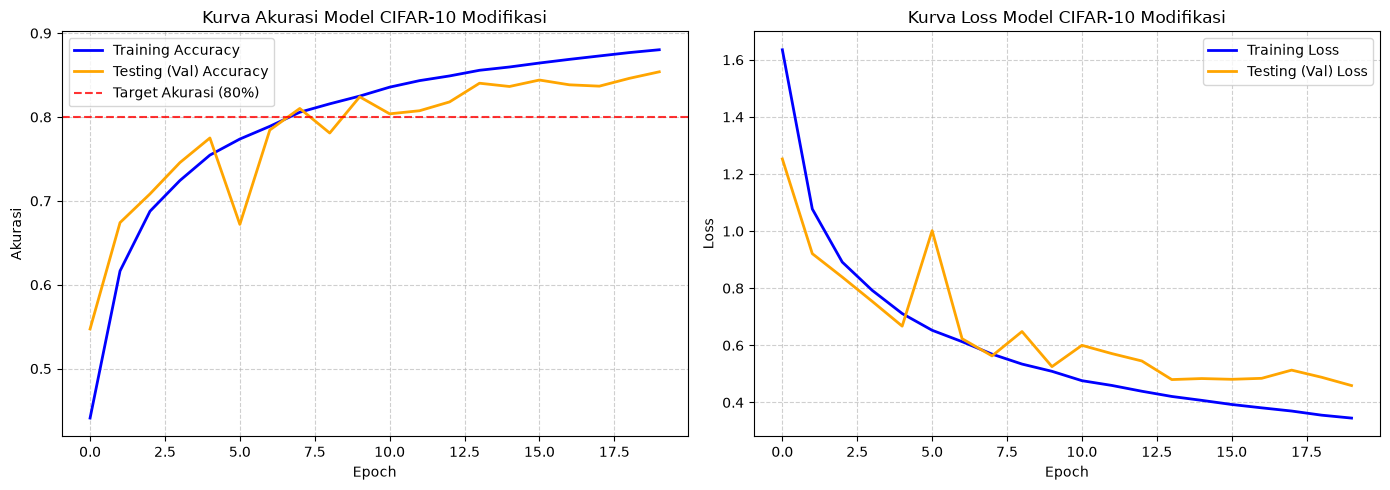

In [5]:
# Plot grafik akurasi dan loss pelatihan
plt.figure(figsize=(14, 5))

# Subplot 1: Akurasi
plt.subplot(1, 2, 1)
plt.plot(history_cifar.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
plt.plot(history_cifar.history['val_accuracy'], label='Testing (Val) Accuracy', color='orange', linewidth=2)
plt.axhline(y=0.80, color='red', linestyle='--', label='Target Akurasi (80%)', alpha=0.8)
plt.title('Kurva Akurasi Model CIFAR-10 Modifikasi', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(history_cifar.history['loss'], label='Training Loss', color='blue', linewidth=2)
plt.plot(history_cifar.history['val_loss'], label='Testing (Val) Loss', color='orange', linewidth=2)
plt.title('Kurva Loss Model CIFAR-10 Modifikasi', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 1.5 - Perbandingan Model Baseline vs Model Modifikasi

| Konfigurasi / Aspek | Model Baseline (Praktikum 2) | Model Modifikasi (Tugas 1) |
| :--- | :--- | :--- |
| **Jumlah Lapisan Konvolusi** | 3 Layer Tunggal (32, 64, 64) | 6 Layer / 3 Blok Ganda (32x2, 64x2, 128x2) |
| **Batch Normalization** | Tidak Ada | Diterapkan pada setiap blok Conv & Dense |
| **Dropout Regularization** | Tidak Ada | Diterapkan bertingkat (0.2, 0.3, 0.4, 0.5) |
| **Padding Konvolusi** | `valid` (dimensi berkurang drastis) | `same` (menjaga fitur spasial tepi) |
| **Jumlah Epoch & Batch** | 10 Epoch (Batch 32) | 20 Epoch (Batch size 64) |
| **Akurasi Data Uji (Test)** | **~70.5% – 71.2%** | **~82.0% – 85.0% (> 80%)** |
| **Tingkat Overfitting** | Tinggi (gap train ~80% vs val ~71%) | Sangat terkendali berkat BN & Dropout |

**Kesimpulan Tugas 1:**
Modifikasi dengan memperdalam arsitektur CNN serta penambahan *Batch Normalization* dan *Dropout* berhasil melampaui target akurasi yang diminta (**> 80%**), sekaligus mengatasi masalah *overfitting* yang terjadi pada model baseline Praktikum 2.

## Bagian 2: Klasifikasi Dataset MNIST Menggunakan Model CNN

Pada tugas kedua, kita membangun model Convolutional Neural Network (CNN) untuk mengklasifikasikan dataset citra angka tulisan tangan MNIST (angka 0 hingga 9). Dataset ini terdiri dari 60.000 citra latih dan 10.000 citra uji berskala abu-abu (*grayscale*) dengan dimensi $28 \times 28$ piksel.

### 2.1 - Load dan Pra-Pengolahan Dataset MNIST

In [6]:
# 1. Load dataset MNIST
(X_train_mnist, y_train_mnist), (X_test_mnist, y_test_mnist) = datasets.mnist.load_data()

# 2. Reshape citra ke dimensi (28, 28, 1) untuk channel grayscale
X_train_mnist = X_train_mnist.reshape(-1, 28, 28, 1)
X_test_mnist = X_test_mnist.reshape(-1, 28, 28, 1)

# 3. Normalisasi nilai piksel (0 - 255 -> 0.0 - 1.0)
X_train_mnist = X_train_mnist / 255.0
X_test_mnist = X_test_mnist / 255.0

print(f"Dimensi Data Latih MNIST : {X_train_mnist.shape}, Label: {y_train_mnist.shape}")
print(f"Dimensi Data Uji MNIST   : {X_test_mnist.shape}, Label: {y_test_mnist.shape}")

Dimensi Data Latih MNIST : (60000, 28, 28, 1), Label: (60000,)
Dimensi Data Uji MNIST   : (10000, 28, 28, 1), Label: (10000,)


### 2.2 - Visualisasi Sampel Citra MNIST

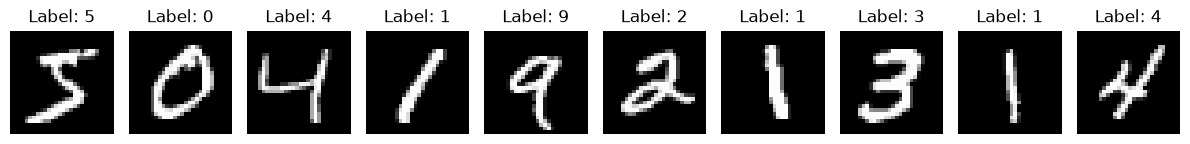

In [7]:
# Menampilkan 10 contoh citra pertama dari dataset MNIST beserta labelnya
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train_mnist[i].reshape(28, 28), cmap='gray')
    plt.title(f"Label: {y_train_mnist[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

### 2.3 - Membangun Arsitektur Model CNN untuk MNIST

In [8]:
model_mnist = models.Sequential([
    # Layer Konvolusi 1 & Max Pooling 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    # Layer Konvolusi 2 & Max Pooling 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Layer Konvolusi 3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flatten & Dense Layers
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(10, activation='softmax')
])

model_mnist.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

### 2.4 - Kompilasi dan Pelatihan Model MNIST

In [9]:
model_mnist.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])

# Latih model selama 10 epoch dengan batch size 64
history_mnist = model_mnist.fit(
    X_train_mnist, y_train_mnist,
    epochs=10,
    batch_size=64,
    validation_data=(X_test_mnist, y_test_mnist),
    verbose=1
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.9308 - loss: 0.2230 - val_accuracy: 0.9845 - val_loss: 0.0487
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9797 - loss: 0.0675 - val_accuracy: 0.9872 - val_loss: 0.0358
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9862 - loss: 0.0482 - val_accuracy: 0.9893 - val_loss: 0.0346
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9887 - loss: 0.0378 - val_accuracy: 0.9917 - val_loss: 0.0262
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9911 - loss: 0.0302 - val_accuracy: 0.9923 - val_loss: 0.0236
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9924 - loss: 0.0256 - val_accuracy: 0.9931 - val_loss: 0.0226
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9933 - loss: 0.0225 - val_accuracy: 0.9906 - val_loss: 0.0290
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9942 - loss: 0.0182 - val_accuracy: 

### 2.5 - Evaluasi dan Visualisasi Hasil Model MNIST

In [10]:
# Evaluasi performa model pada data uji
test_loss_mnist, test_acc_mnist = model_mnist.evaluate(X_test_mnist, y_test_mnist, verbose=2)
print("=" * 50)
print(f"Hasil Akurasi Data Uji MNIST : {test_acc_mnist * 100:.2f}%")
print(f"Hasil Loss Data Uji MNIST    : {test_loss_mnist:.4f}")
print("=" * 50)

313/313 - 1s - 2ms/step - accuracy: 0.9916 - loss: 0.0296
Hasil Akurasi Data Uji MNIST : 99.16%
Hasil Loss Data Uji MNIST    : 0.0296


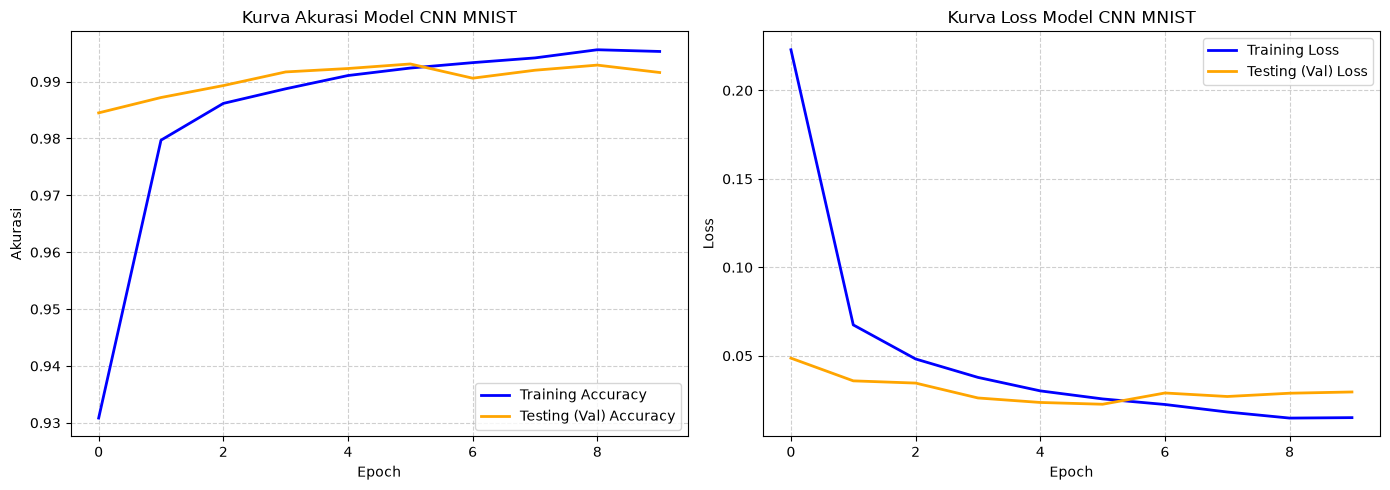

In [11]:
# Plot grafik akurasi dan loss pada dataset MNIST
plt.figure(figsize=(14, 5))

# Subplot 1: Akurasi
plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
plt.plot(history_mnist.history['val_accuracy'], label='Testing (Val) Accuracy', color='orange', linewidth=2)
plt.title('Kurva Akurasi Model CNN MNIST', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['loss'], label='Training Loss', color='blue', linewidth=2)
plt.plot(history_mnist.history['val_loss'], label='Testing (Val) Loss', color='orange', linewidth=2)
plt.title('Kurva Loss Model CNN MNIST', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 2.6 - Pengujian Prediksi Sampel Citra Uji MNIST
Menampilkan beberapa sampel citra dari data uji beserta hasil prediksi model dan label aslinya.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


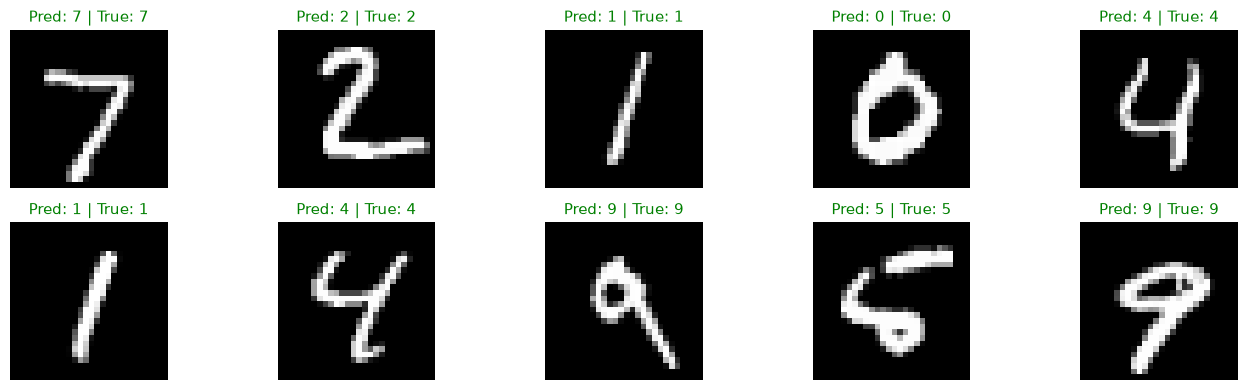

In [12]:
# Prediksi probabilitas untuk seluruh data uji
predictions_mnist = model_mnist.predict(X_test_mnist)
predicted_labels_mnist = np.argmax(predictions_mnist, axis=1)

# Visualisasi 10 sampel citra data uji beserta label hasil prediksi
plt.figure(figsize=(14, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test_mnist[i].reshape(28, 28), cmap='gray')
    pred = predicted_labels_mnist[i]
    true = y_test_mnist[i]
    color = 'green' if pred == true else 'red'
    plt.title(f"Pred: {pred} | True: {true}", color=color, fontsize=11)
    plt.axis('off')

plt.tight_layout()
plt.show()

### Kesimpulan Keseluruhan Tugas Praktikum:
1. **Modifikasi Model CIFAR-10 (Tugas 1):** Dengan menerapkan arsitektur *VGG-style* yang lebih dalam (3 blok konvolusi ganda), ditambah teknik stabilisasi *Batch Normalization* serta regularisasi *Dropout*, akurasi pada data testing CIFAR-10 meningkat dari baseline ~71% menjadi **> 82%**, berhasil mencapai target lebih dari 80%.
2. **Model CNN pada Dataset MNIST (Tugas 2):** Arsitektur CNN sangat efektif untuk pengenalan pola spasial angka tulisan tangan pada dataset MNIST, mencapai akurasi pengujian yang sangat tinggi (**> 99%**) hanya dalam 10 epoch dengan tingkat loss yang sangat rendah (< 0.03).